# 01 · Exploratory Data Analysis
### IT3091 Machine Learning · Group 2026-AI-42 · Bank Marketing: ranking clients for a term-deposit telemarketing campaign

**Track:** Guided Data Track (group digit 2, Banking & Finance)  |  **Primary lens:** Campaign response prediction  |  **Secondary lens:** Customer segment prioritisation
**Dataset:** UCI Bank Marketing, `bank-additional-full.csv` (Moro, Cortez & Rita, 2014)  |  **Led by:** Problem framing & EDA lead

---

## What this notebook has to settle

A bank's call centre cannot phone every client on its list, so the campaign manager needs to know **who to call first**. The model that will answer this is built in notebooks 03-08. Before any model is trained, the data has to answer six practical questions, and each answer feeds one decision in the preprocessing notebook (02):

| # | Question the bank would ask | Section | What it decides |
|---|---|---|---|
| Q1 | What is one row, what does each column mean, and can the numbers be trusted? | 1-3 | cleaning rules |
| Q2 | Which columns would **not exist** at the moment the call list is built? | 2 | leakage guard (`duration`) |
| Q3 | How rare is a subscription, and what does that do to the way we measure a model? | 4 | evaluation metrics, imbalance handling |
| Q4 | Which client, campaign and history characteristics separate subscribers from non-subscribers? | 5-8, 11 | which features matter, how to encode them |
| Q5 | Does the picture stay the same over the two and a half years of calls? | 9 | validation design (chronological split) |
| Q6 | Are some columns redundant or just proxies for the calendar? | 10 | macro-indicator policy |

### How every section is written
**Purpose** (why the bank cares) → **Evidence** (the code and its output) → **Reading** (what the output says in plain words) → **Decision** (what it changes downstream). The final sections collect the findings in an **insight log** (section 12) and a **hand-off table to preprocessing** (section 13).

> The written readings were composed against the official file. If a number in your own output disagrees with a sentence, trust your output and correct the sentence before submitting.
>
> All statistics below are computed on the **full file**. EDA describes the data; it does not fit a model, so nothing here is evaluated as a prediction. Anything that is later *learned* (medians, scalers, encoders, models) is fitted on the training period only, in notebooks 02-08.

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))          # lets the notebook import the project code in src/
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display

from src.config import *
from src.data.loading import load_raw, fingerprint
from src.data.splits import deduplicate, chronological_split, describe_split
from src.data import eda_checks as ec
from src.plotting import set_style, save_fig, rate_bars

set_style()
pd.set_option("display.max_columns", 60, "display.width", 170, "display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

---
## 1 · Load the data and record exactly which file we used

**Purpose.** Two people running this notebook must be analysing the same data. We load the file untouched (no cleaning yet) and print a content fingerprint that can be compared across machines.

**What one row is.** The file has **no client identifier**. One row is one *telemarketing contact* (a call outcome for a client during a campaign), so the same person could appear more than once and we cannot tell. We therefore treat each row as one observation (unit of analysis stated in the initial submission, section 8) and list this as a limitation.

**Dataset version.** The initial submission proposed `bank-full.csv` (16 inputs). This project models `bank-additional-full.csv` (20 inputs, 41,188 rows) because it keeps the same bank, campaign and target but adds the five macro-economic indicators that the proposal said it would revisit if EDA suggested they were needed. The proposal's version is compared head-to-head in notebook 03 (section 5) instead of being assumed.

In [2]:
raw = load_raw()
print("Shape                    :", raw.shape, "(rows x columns)")
print("SHA-256 content fingerprint:", fingerprint(raw))
print("Source                   : https://archive.ics.uci.edu/dataset/222/bank+marketing")
raw.head()

Loading local file: bank-additional-full.csv
Shape                    : (41188, 21) (rows x columns)
SHA-256 content fingerprint: 00de77bb3ece5d5fdfdd09ec12392284dac89d6d877ec1659092eb5b3522abe1
Source                   : https://archive.ics.uci.edu/dataset/222/bank+marketing


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no


In [3]:
# Checkpoints taken from the group's first run of the official file. If any line says MISMATCH you are analysing a
# different file (or a modified copy) and the numbers quoted in the write-up will not match yours.
checks = {
    "rows": (len(raw), 41188),
    "columns": (raw.shape[1], 21),
    "exact duplicate rows": (int(raw.duplicated().sum()), 12),
    "subscription rate": (round(float((raw["y"] == "yes").mean()), 4), 0.1127),
    "pdays == 999 share": (round(float((raw["pdays"] == 999).mean()), 4), 0.9632),
}
for k, (got, want) in checks.items():
    print(f"{'OK      ' if got == want else 'MISMATCH'} {k:<22} got {got!s:<8} expected {want}")

OK       rows                   got 41188    expected 41188
OK       columns                got 21       expected 21
OK       exact duplicate rows   got 12       expected 12
OK       subscription rate      got 0.1127   expected 0.1127
OK       pdays == 999 share     got 0.9632   expected 0.9632


In [4]:
eda = raw.copy()
eda["y_bin"] = (eda["y"] == "yes").astype(int)          # 1 = subscribed
BASE = eda["y_bin"].mean()                               # overall subscription rate, used as the reference line everywhere

---
## 2 · Data dictionary and the "would we know this before the call?" audit

**Purpose.** The target is the outcome of a call, so any column that is only recorded **during or after** the call can accidentally contain the answer. A column can look excellent in a notebook and be useless to a campaign manager who has to build the call list *before* dialling. This audit is the single most important data-understanding step in the project.

We classify every column by **when its value becomes known**:

| Availability class | Meaning | Columns |
|---|---|---|
| **A. Known before any contact** | Stored in the client record or the previous-campaign history | client attributes, `pdays`, `previous`, `poutcome` |
| **B. Known when the call is planned** | Decided by the bank when it schedules the call | `contact`, `month`, `day_of_week` |
| **C. Known only after the call** | Produced by the call itself | **`duration`** |
| **D. Grey zone: use with care** | Available, but with a caveat that must be tested | `campaign` (count includes the current call), macro indicators (identical for every client on a given day) |

In [5]:
dictionary = pd.DataFrame([
    # column, group, type, meaning, available when?, treatment
    ("age", "Client", "numeric", "Client age in years", "A. before contact", "Keep (numeric)"),
    ("job", "Client", "categorical", "Type of job (12 levels, includes 'unknown')", "A. before contact", "Keep (one-hot)"),
    ("marital", "Client", "categorical", "Marital status (includes 'unknown')", "A. before contact", "Keep; sensitive, audited in notebook 07"),
    ("education", "Client", "categorical", "Education level (includes 'unknown')", "A. before contact", "Re-coded as an ordinal number"),
    ("default", "Client", "categorical", "Has credit in default? yes / no / unknown", "A. before contact", "Keep (one-hot, 'unknown' kept)"),
    ("housing", "Client", "categorical", "Has a housing loan?", "A. before contact", "Keep (one-hot)"),
    ("loan", "Client", "categorical", "Has a personal loan?", "A. before contact", "Keep (one-hot)"),
    ("contact", "Campaign", "categorical", "Contact channel: cellular / telephone", "B. when planned", "Keep (one-hot)"),
    ("month", "Campaign", "categorical", "Month of the last contact", "B. when planned", "Keep (one-hot); confounded with year, see section 9"),
    ("day_of_week", "Campaign", "categorical", "Weekday of the last contact", "B. when planned", "Keep (one-hot)"),
    ("duration", "Campaign", "numeric", "Length of the last call in seconds", "C. only after the call", "EXCLUDE (leakage)"),
    ("campaign", "Campaign", "numeric", "Number of contacts to this client in THIS campaign, including the last", "D. grey zone", "Keep + log copy; sensitivity test in notebook 02"),
    ("pdays", "History", "numeric", "Days since the client was last contacted in a PREVIOUS campaign; 999 = never", "A. before contact", "Flag + replace placeholder"),
    ("previous", "History", "numeric", "Number of contacts before this campaign", "A. before contact", "Keep (numeric)"),
    ("poutcome", "History", "categorical", "Outcome of the previous campaign", "A. before contact", "Keep (one-hot)"),
    ("emp.var.rate", "Macro", "numeric", "Employment variation rate (quarterly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("cons.price.idx", "Macro", "numeric", "Consumer price index (monthly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("cons.conf.idx", "Macro", "numeric", "Consumer confidence index (monthly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("euribor3m", "Macro", "numeric", "3-month Euribor interest rate (daily)", "D. grey zone", "Excluded by default (time proxy)"),
    ("nr.employed", "Macro", "numeric", "Number of employees (quarterly)", "D. grey zone", "Excluded by default (time proxy)"),
    ("y", "Target", "binary", "Did the client subscribe to a term deposit? yes / no", "outcome", "Target (1 = yes)"),
], columns=["column", "group", "type", "meaning", "known when?", "treatment"]).set_index("column")

def observed(c):
    s = raw[c]
    return f"{s.min():g} to {s.max():g}" if pd.api.types.is_numeric_dtype(s) else f"{s.nunique()} levels"
dictionary["observed in data"] = [observed(c) for c in dictionary.index]
dictionary.to_csv(TABLES_DIR / "data_dictionary.csv")
dictionary

,group,type,meaning,known when?,treatment,observed in data
column,,,,,,
age,Client,numeric,Client age in years,A. before contact,Keep (numeric),17 to 98
job,Client,categorical,"Type of job (12 levels, includes 'unknown')",A. before contact,Keep (one-hot),12 levels
marital,Client,categorical,Marital status (includes 'unknown'),A. before contact,"Keep; sensitive, audited in notebook 07",4 levels
education,Client,categorical,Education level (includes 'unknown'),A. before contact,Re-coded as an ordinal number,8 levels
default,Client,categorical,Has credit in default? yes / no / unknown,A. before contact,"Keep (one-hot, 'unknown' kept)",3 levels
housing,Client,categorical,Has a housing loan?,A. before contact,Keep (one-hot),3 levels
loan,Client,categorical,Has a personal loan?,A. before contact,Keep (one-hot),3 levels
contact,Campaign,categorical,Contact channel: cellular / telephone,B. when planned,Keep (one-hot),2 levels
month,Campaign,categorical,Month of the last contact,B. when planned,"Keep (one-hot); confounded with year, see section 9",10 levels


**Reading.** Eighteen of the twenty inputs are legitimate before-the-call information (classes A and B) or a flagged grey-zone column. Two need an explicit decision:

* **`duration` is excluded from every deployable model.** The submission already named it as the leakage risk (sections 7 and 10). Section 6 shows how strongly it separates the classes, and notebook 02 (section 7) measures the "illusion of skill" it would create.
* **`campaign` is allowed but flagged.** It counts *all* calls to the client in this campaign, including the last one. Clients who say yes stop being called, while clients who say no keep being called, so the final count carries a little information about the outcome. Notebook 02 tests whether removing it changes the result.
* **The macro indicators are identical for every client contacted on the same day**, so they describe the *calendar*, not the *client*. Section 9-10 tests whether they act as a clock.

---
## 3 · Data quality audit

**Purpose.** A model trained on mis-recorded or ambiguous values learns the recording habits rather than the clients. Each check below states the *question*, shows the *evidence*, and ends in an *action* that notebook 02 implements.

### 3.1 One-glance scorecard

In [6]:
scorecard = ec.quality_scorecard(raw, CATEGORICAL_RAW)
scorecard.to_csv(TABLES_DIR / "data_quality_scorecard.csv")
scorecard

,result,severity,action
check,,,
Exact duplicate rows,"12 of 41,188",minor,"drop, keep first, keep order"
True missing cells (NaN),0,ok,none needed
Hidden missing values ('unknown'),"default 20.9%, education 4.2%, housing 2.4%, loan 2.4%, job 0.8%, marital 0.2%",check,keep as own category; education -> NaN + indicator
Sentinel value pdays = 999,96.3% of rows,check,flag + replace by 0
Constant columns,none,ok,none needed
Post-call column present,duration (call length in seconds),critical,exclude from every deployable model
Zero-length calls,4 rows with duration = 0,minor,irrelevant once duration is excluded
Age range,17 to 98 years; 5 clients under 18,ok,"keep; age stays numeric (sensitive attribute, audited in notebook 07)"


### 3.2 Exact duplicate rows
**Question.** Are some contacts recorded twice? Two identical rows in train and test would let a model "remember" a row.

In [7]:
dup_mask = raw.duplicated(keep=False)
dups = raw[dup_mask]
print(f"{int(raw.duplicated().sum())} rows repeat an earlier row exactly ({dup_mask.sum()} rows are involved in total).")
print("Row positions of the repeated pairs (consecutive positions mean they were recorded back to back):",
      sorted(dups.index.tolist())[:24], "...")
display(dups.head(6))

12 rows repeat an earlier row exactly (24 rows are involved in total).
Row positions of the repeated pairs (consecutive positions mean they were recorded back to back): [1265, 1266, 12260, 12261, 14155, 14234, 16819, 16956, 18464, 18465, 20072, 20216, 20531, 20534, 25183, 25217, 28476, 28477, 32505, 32516, 36950, 36951, 38255, 38281] ...


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.100,93.994,-36.400,4.855,"5,191.000",no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,124,1,999,0,nonexistent,1.100,93.994,-36.400,4.855,"5,191.000",no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.400,93.918,-42.700,4.966,"5,228.100",no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.400,93.918,-42.700,4.966,"5,228.100",no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.400,93.918,-42.700,4.962,"5,228.100",no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.400,93.918,-42.700,4.962,"5,228.100",no


**Reading.** Duplicates are a tiny share of the file. Because there is no client identifier, an identical pair could in principle be two different clients with the same attributes calling on the same day, but that is very unlikely when 20 attributes (including the exact Euribor value) all match. **Decision:** drop the later copy and keep the original order (order is time, so it must not change).

### 3.3 Hidden missing values: the label `unknown`
**Question.** The file has no empty cells, but that does not mean nothing is missing. Missing answers are written as the text `unknown`, which pandas treats as a normal category.

True NaN cells in the whole file: 0


,unknown_rows,unknown_pct
column,,
default,8597,20.870
education,1731,4.200
housing,990,2.400
loan,990,2.400
job,330,0.800
marital,80,0.190


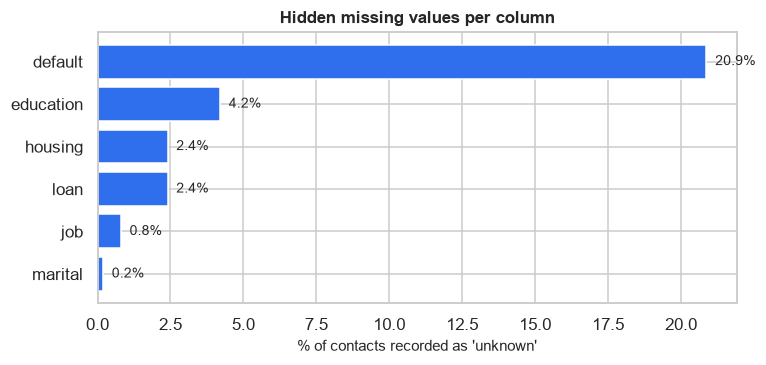

In [8]:
unk = ec.unknown_table(raw, CATEGORICAL_RAW)
unk_cols = unk[unk["unknown_rows"] > 0]
print("True NaN cells in the whole file:", int(raw.isna().sum().sum()))
display(unk_cols)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(unk_cols.index[::-1], unk_cols["unknown_pct"][::-1], color=C_MAIN)
for i, v in enumerate(unk_cols["unknown_pct"][::-1]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of contacts recorded as 'unknown'"); ax.set_title("Hidden missing values per column")
save_fig("eda_unknown_share")

### 3.4 Is `unknown` just noise, or does it carry information?
**Question.** If clients with an `unknown` answer subscribe at a *different* rate from clients with a known answer, then deleting those rows or guessing the most common value (imputing the mode) would throw away signal. If the rates are the same, `unknown` is harmless noise. We compare the two groups for every column that has `unknown`, with a chi-square test (a p-value below 0.01 is treated as a real difference).

In [9]:
rows = []
for c in unk_cols.index:
    is_unk = eda[c] == "unknown"
    ct = pd.crosstab(is_unk, eda["y_bin"])
    p = stats.chi2_contingency(ct, correction=False)[1] if ct.shape == (2, 2) else np.nan
    rows.append(dict(column=c, contacts_unknown=int(is_unk.sum()),
                     rate_unknown_pct=100 * eda.loc[is_unk, "y_bin"].mean(), rate_known_pct=100 * eda.loc[~is_unk, "y_bin"].mean(),
                     p_value=p))
unk_info = pd.DataFrame(rows).set_index("column")
unk_info["difference_pp"] = unk_info["rate_unknown_pct"] - unk_info["rate_known_pct"]
unk_info["verdict"] = np.where(unk_info["p_value"] < 0.01, "differs: keep as its own category", "no clear difference")
display(unk_info.round(4))
for c, r in unk_info.iterrows():
    direction = "lower" if r["difference_pp"] < 0 else "higher"
    print(f"{c:<10}: 'unknown' clients subscribe {abs(r['difference_pp']):.1f} points {direction} than clients with a recorded answer ({r['verdict']}).")

,contacts_unknown,rate_unknown_pct,rate_known_pct,p_value,difference_pp,verdict
column,,,,,,
default,8597,5.153,12.878,0.000,-7.725,differs: keep as its own category
education,1731,14.500,11.123,0.000,3.377,differs: keep as its own category
housing,990,10.808,11.277,0.645,-0.469,no clear difference
loan,990,10.808,11.277,0.645,-0.469,no clear difference
job,330,11.212,11.266,0.976,-0.054,no clear difference
marital,80,15.000,11.258,0.290,3.742,no clear difference


default   : 'unknown' clients subscribe 7.7 points lower than clients with a recorded answer (differs: keep as its own category).
education : 'unknown' clients subscribe 3.4 points higher than clients with a recorded answer (differs: keep as its own category).
housing   : 'unknown' clients subscribe 0.5 points lower than clients with a recorded answer (no clear difference).
loan      : 'unknown' clients subscribe 0.5 points lower than clients with a recorded answer (no clear difference).
job       : 'unknown' clients subscribe 0.1 points lower than clients with a recorded answer (no clear difference).
marital   : 'unknown' clients subscribe 3.7 points higher than clients with a recorded answer (no clear difference).


### 3.5 Do the `unknown` answers occur together?
**Question.** If `unknown` marks the *same rows* in several columns, those rows are probably incomplete client records (a data-collection issue) rather than independent gaps, and imputing each column separately would be wrong.

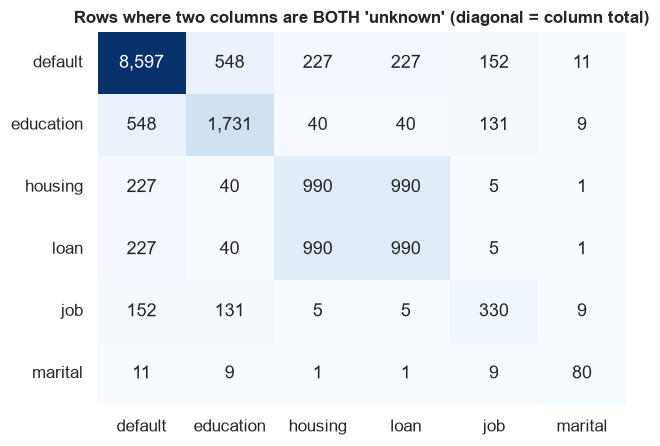

housing and loan are both 'unknown' in 990 rows = 100% of the housing 'unknown' rows.


In [10]:
unk_ind = pd.DataFrame({c: (eda[c] == "unknown").astype(int) for c in unk_cols.index})
co = unk_ind.T.dot(unk_ind)
plt.figure(figsize=(6.2, 4.4))
sns.heatmap(co, annot=True, fmt=",d", cmap="Blues", cbar=False)
plt.title("Rows where two columns are BOTH 'unknown' (diagonal = column total)")
save_fig("eda_unknown_cooccurrence")
if {"housing", "loan"} <= set(unk_ind.columns):
    both = int(((unk_ind["housing"] == 1) & (unk_ind["loan"] == 1)).sum())
    print(f"housing and loan are both 'unknown' in {both:,} rows = {100 * both / max(unk_ind['housing'].sum(), 1):.0f}% of the housing 'unknown' rows.")

**Reading and decision.** The sharing pattern tells us whether to treat gaps as one problem or several. The treatment is the same either way: **`unknown` is kept as its own category** (it is a real, observable state of the client record and may be informative), nothing is imputed with the mode, and no rows are dropped. The one exception is `education`, which is turned into an ordered number (illiterate < basic < high school < professional < university); there `unknown` cannot be placed on the scale, so it becomes a true missing value that is median-imputed *inside the pipeline* together with a missing-indicator column, so the model can still tell "unknown" apart.

`default = unknown` is by far the largest gap. Only a handful of clients are recorded as `default = yes`, so for the bank this column behaves more like "credit status verified / not verified" than a default flag.

### 3.6 The placeholder `pdays = 999`
**Question.** `pdays` is "days since the previous campaign contact". Which value means "never contacted before", and does the rest of the history agree?

In [11]:
hist = ec.history_consistency(eda)
display(hist)
contacted = eda[eda["pdays"] != 999]
print(f"pdays == 999 in {100 * (eda['pdays'] == 999).mean():.2f}% of rows. Among the {len(contacted):,} previously contacted clients pdays runs from "
      f"{contacted['pdays'].min()} to {contacted['pdays'].max()} days (median {contacted['pdays'].median():.0f}).")
print("Mean of pdays if 999 is wrongly treated as a number:", round(eda["pdays"].mean(), 1), "days  vs. the real median among contacted clients:", contacted["pdays"].median())

,rows
pdays == 999,39673
previous == 0,35563
poutcome == nonexistent,35563
all three agree,37078
pdays != 999 but previous == 0,0
pdays == 999 but previous > 0,4110


pdays == 999 in 96.32% of rows. Among the 1,515 previously contacted clients pdays runs from 0 to 27 days (median 6).
Mean of pdays if 999 is wrongly treated as a number: 962.5 days  vs. the real median among contacted clients: 6.0


**Reading and decision.** The three history columns describe one fact (was the client contacted in an earlier campaign?) and they agree row by row. `999` is a **code, not a number of days**; fed to a model as a number it would say "a never-contacted client was last contacted 999 days ago", which distorts distances and linear coefficients. **Decision:** add the flag `was_contacted_before` and replace the placeholder by 0 (the flag carries the information).

### 3.7 Ranges and outliers
**Question.** Are there impossible values, and are long right tails going to dominate a linear model or a neural network?

,min,median,p99,max,skew,outliers_iqr,outliers_pct
column,,,,,,,
age,17,38.000,71.000,98,0.780,469,1.140
campaign,1,2.000,14.000,56,4.760,2406,5.840
previous,0,0.000,2.000,7,3.830,5625,13.660
duration,0,180.000,"1,271.130",4918,3.260,2963,7.190


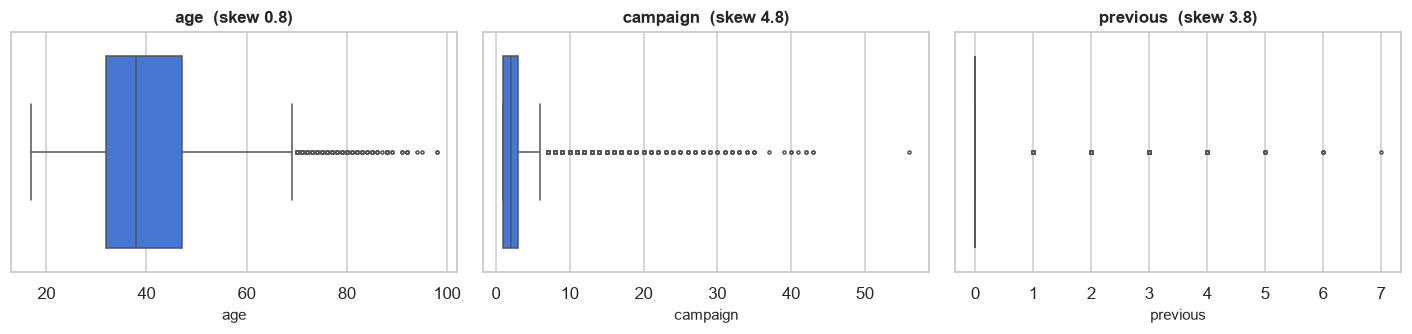

Clients with campaign >= 20 calls: 187 (max 56). Clients under 18: 5.


In [12]:
outl = ec.iqr_outlier_table(eda, ["age", "campaign", "previous", "duration"])
display(outl)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, c in zip(ax, ["age", "campaign", "previous"]):
    sns.boxplot(x=eda[c], ax=a, color=C_MAIN, fliersize=2); a.set_title(f"{c}  (skew {eda[c].skew():.1f})")
plt.tight_layout(); save_fig("eda_outlier_boxplots")
print(f"Clients with campaign >= 20 calls: {(eda['campaign'] >= 20).sum()} (max {eda['campaign'].max()}). Clients under 18: {(eda['age'] < 18).sum()}.")

**Reading and decision.** `campaign` has a long right tail (a few clients were called dozens of times) and is strongly right-skewed. These are **real behaviour, not errors**, so rows are **not removed**. Tree models are insensitive to the tail; logistic regression and the neural network are not, so a `log(1 + campaign)` copy is added in preprocessing (compared before and after in notebook 02, section 4). `age` is plausible throughout. `previous` is mostly 0 and is kept as is.

### Data-quality verdict
The file is unusually clean (no empty cells, a handful of duplicates, plausible ranges). The real quality issues are *semantic*: hidden missing values (`unknown`), a numeric placeholder (`pdays = 999`) and one post-call column (`duration`). All are handled explicitly in notebook 02.

---
## 4 · The target: how rare is a subscription?

**Purpose.** The share of subscribers decides which metrics are honest. If 9 in 10 clients say no, a model that predicts "no" for everyone is 90% accurate and worth nothing to the bank.

     contacts  share_%
y                     
no      36548   88.730
yes      4640   11.270

Overall subscription rate : 11.27%
Accuracy of 'always say no': 88.73%   <- looks excellent, identifies zero subscribers
Calls the bank makes per subscription when dialling at random: about 8.9


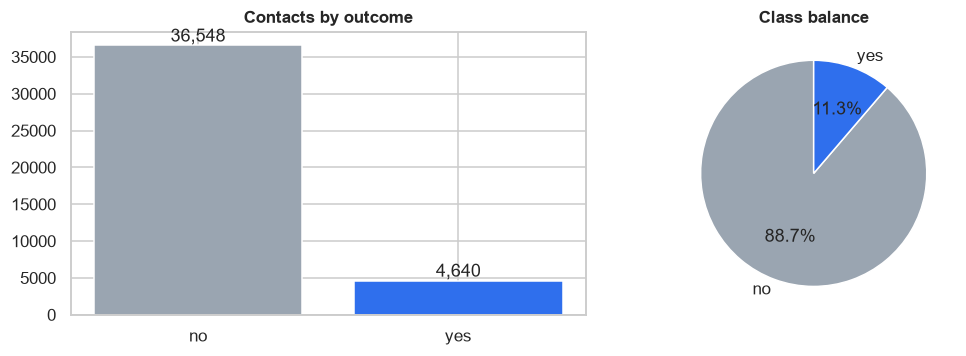

In [13]:
vc = eda["y"].value_counts()
rate = BASE
print(pd.DataFrame({"contacts": vc, "share_%": 100 * vc / vc.sum()}).round(2))
print(f"\nOverall subscription rate : {rate:.2%}")
print(f"Accuracy of 'always say no': {1 - rate:.2%}   <- looks excellent, identifies zero subscribers")
print(f"Calls the bank makes per subscription when dialling at random: about {1 / rate:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].bar(["no", "yes"], [vc["no"], vc["yes"]], color=[C_GREY, C_MAIN]); ax[0].set_title("Contacts by outcome")
for i, v in enumerate([vc["no"], vc["yes"]]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie([vc["no"], vc["yes"]], labels=["no", "yes"], colors=[C_GREY, C_MAIN], autopct="%1.1f%%", startangle=90)
ax[1].set_title("Class balance")
plt.tight_layout(); save_fig("eda_class_balance")

**Reading.** About one contact in nine ends in a subscription (11.27% in the official file), so a random call centre needs roughly **nine calls per sale**. This is exactly the waste the bank wants to reduce.

**Decisions for the rest of the project**
* **Accuracy is not reported as a success measure** (it is shown once, for the dummy model, to demonstrate why).
* Models are compared with **PR-AUC** (focuses on the rare class), **ROC-AUC**, and **budget metrics**: precision, recall and lift among the top `CALL_BUDGET` share of clients, which is what a call centre with limited capacity actually experiences.
* Imbalance handling (class weights, SMOTE, SMOTE-Tomek) is **tested, not assumed**, in notebook 04, always *inside* the training folds.

---
## 5 · Distributions: what does a typical contact look like?

**Purpose.** Before comparing subscribers with non-subscribers we need to know what the overall population looks like (who the bank phones, how often, through which channel), because a pattern among a tiny group cannot guide a whole campaign.

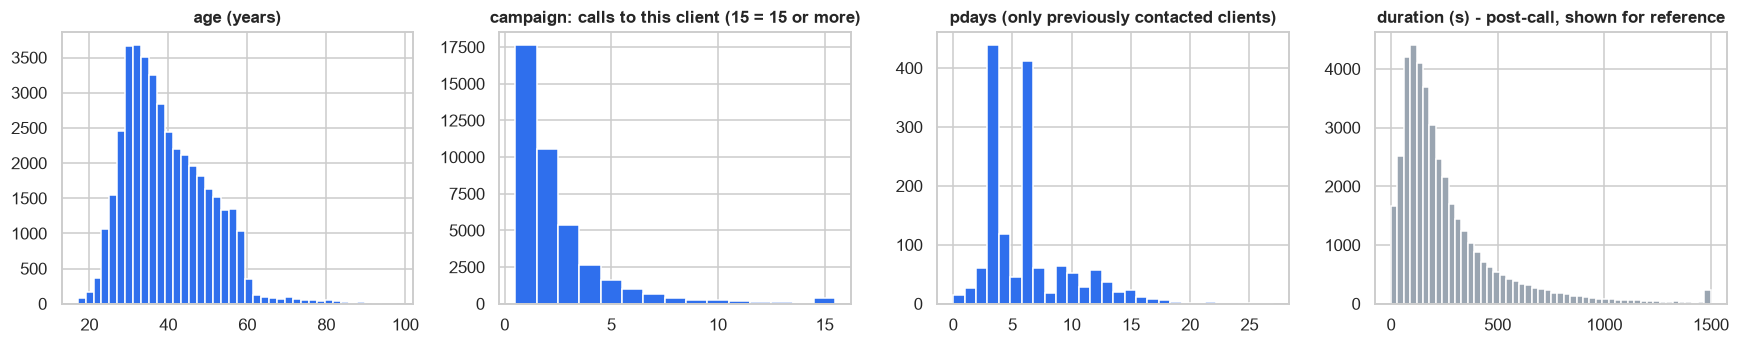

          age  campaign  previous  duration
mean   40.020     2.570     0.170   258.290
median 38.000     2.000     0.000   180.000
skew    0.780     4.760     3.830     3.260


In [14]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.3))
ax[0].hist(eda["age"], bins=40, color=C_MAIN); ax[0].set_title("age (years)")
ax[1].hist(eda["campaign"].clip(upper=15), bins=range(1, 17), color=C_MAIN, align="left"); ax[1].set_title("campaign: calls to this client (15 = 15 or more)")
ax[2].hist(eda.loc[eda["pdays"] != 999, "pdays"], bins=28, color=C_MAIN); ax[2].set_title("pdays (only previously contacted clients)")
ax[3].hist(eda["duration"].clip(upper=1500), bins=50, color=C_GREY); ax[3].set_title("duration (s) - post-call, shown for reference")
plt.tight_layout(); save_fig("eda_numeric_distributions")
print(eda[["age", "campaign", "previous", "duration"]].agg(["mean", "median", "skew"]).round(2))

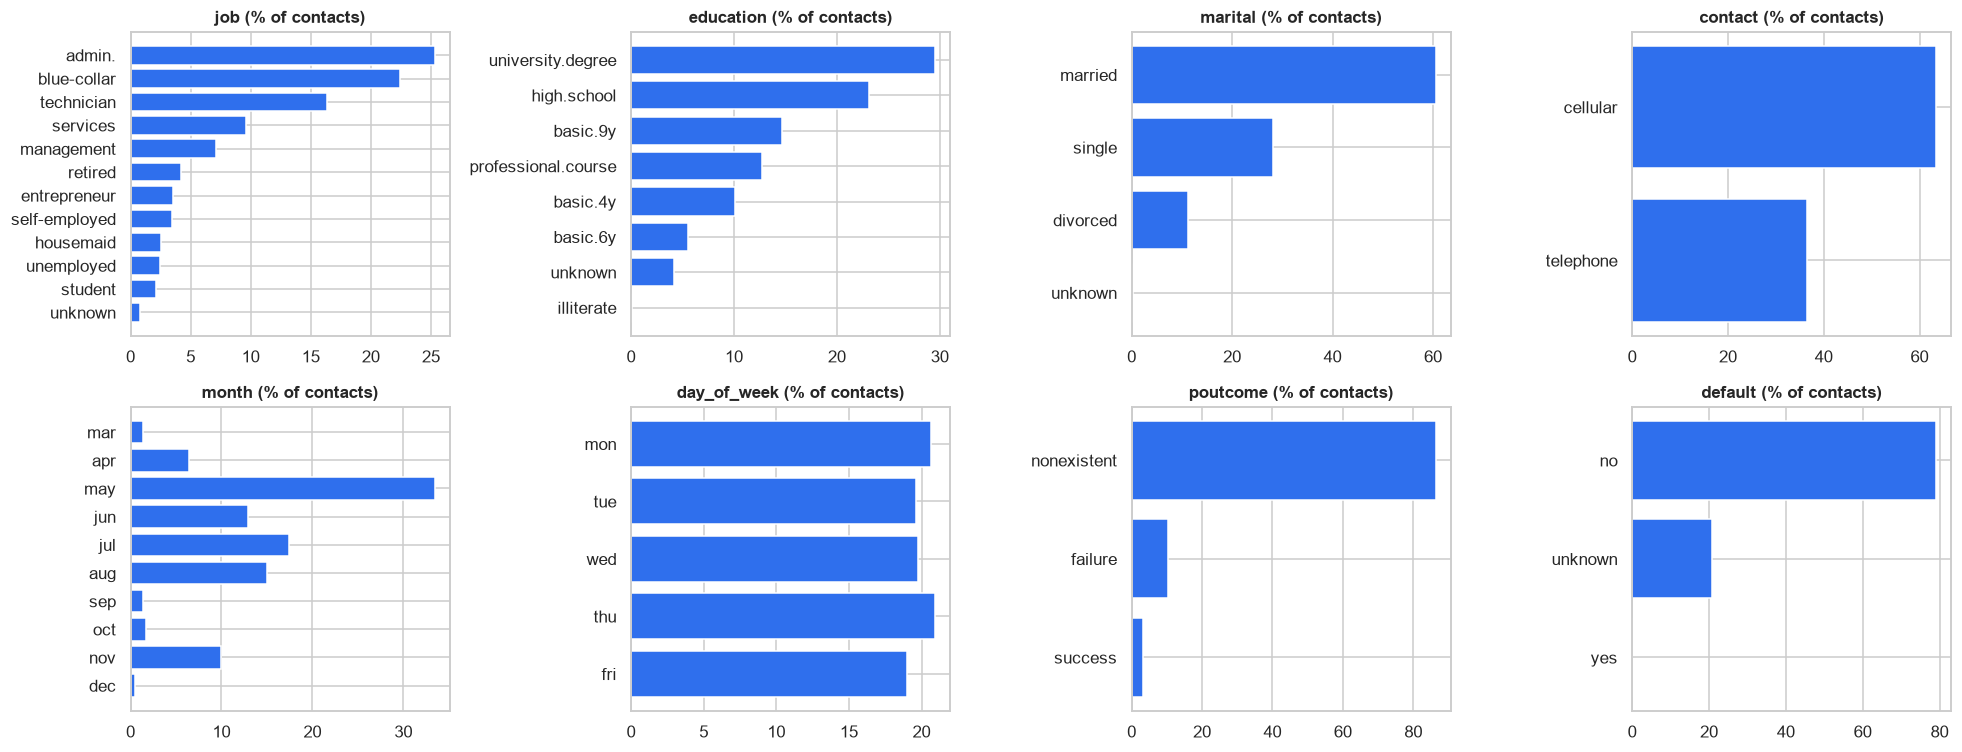

In [15]:
month_present = [m for m in MONTH_ORDER if m in set(eda["month"])]
panels = [("job", None), ("education", None), ("marital", None), ("contact", None),
          ("month", month_present), ("day_of_week", ["mon", "tue", "wed", "thu", "fri"]), ("poutcome", None), ("default", None)]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for a, (c, order) in zip(ax.ravel(), panels):
    vc = eda[c].value_counts(normalize=True) * 100
    vc = vc.reindex(order) if order else vc
    a.barh(vc.index[::-1].astype(str), vc.values[::-1], color=C_MAIN); a.set_title(f"{c} (% of contacts)")
plt.tight_layout(); save_fig("eda_categorical_distributions")

**Reading.** The population is dominated by a few job types, married clients with a university or high-school education, and contact by mobile phone. Three things deserve attention:

1. **`month` is very uneven.** A few summer months carry most of the calls, while other months (March, September, October, December) have very few. Rates computed on small months are noisy; the volume is shown beside every rate from here on.
2. **Almost all clients have never been contacted before** (`poutcome = nonexistent`), so the previous-campaign signal can only matter for a small group.
3. **`campaign` and `duration` are right-skewed**; `age` is roughly bell-shaped with a tail of older clients.

---
## 6 · Who subscribes? Rates by client, campaign and history attributes

**Purpose.** This is the core of the business question. For every attribute we compare the subscription rate of each group with the overall rate (red dashed line). Each bar carries a **95% confidence interval** and the **number of contacts** behind it: a tall bar on 30 contacts is not a finding.

### 6.1 Client attributes

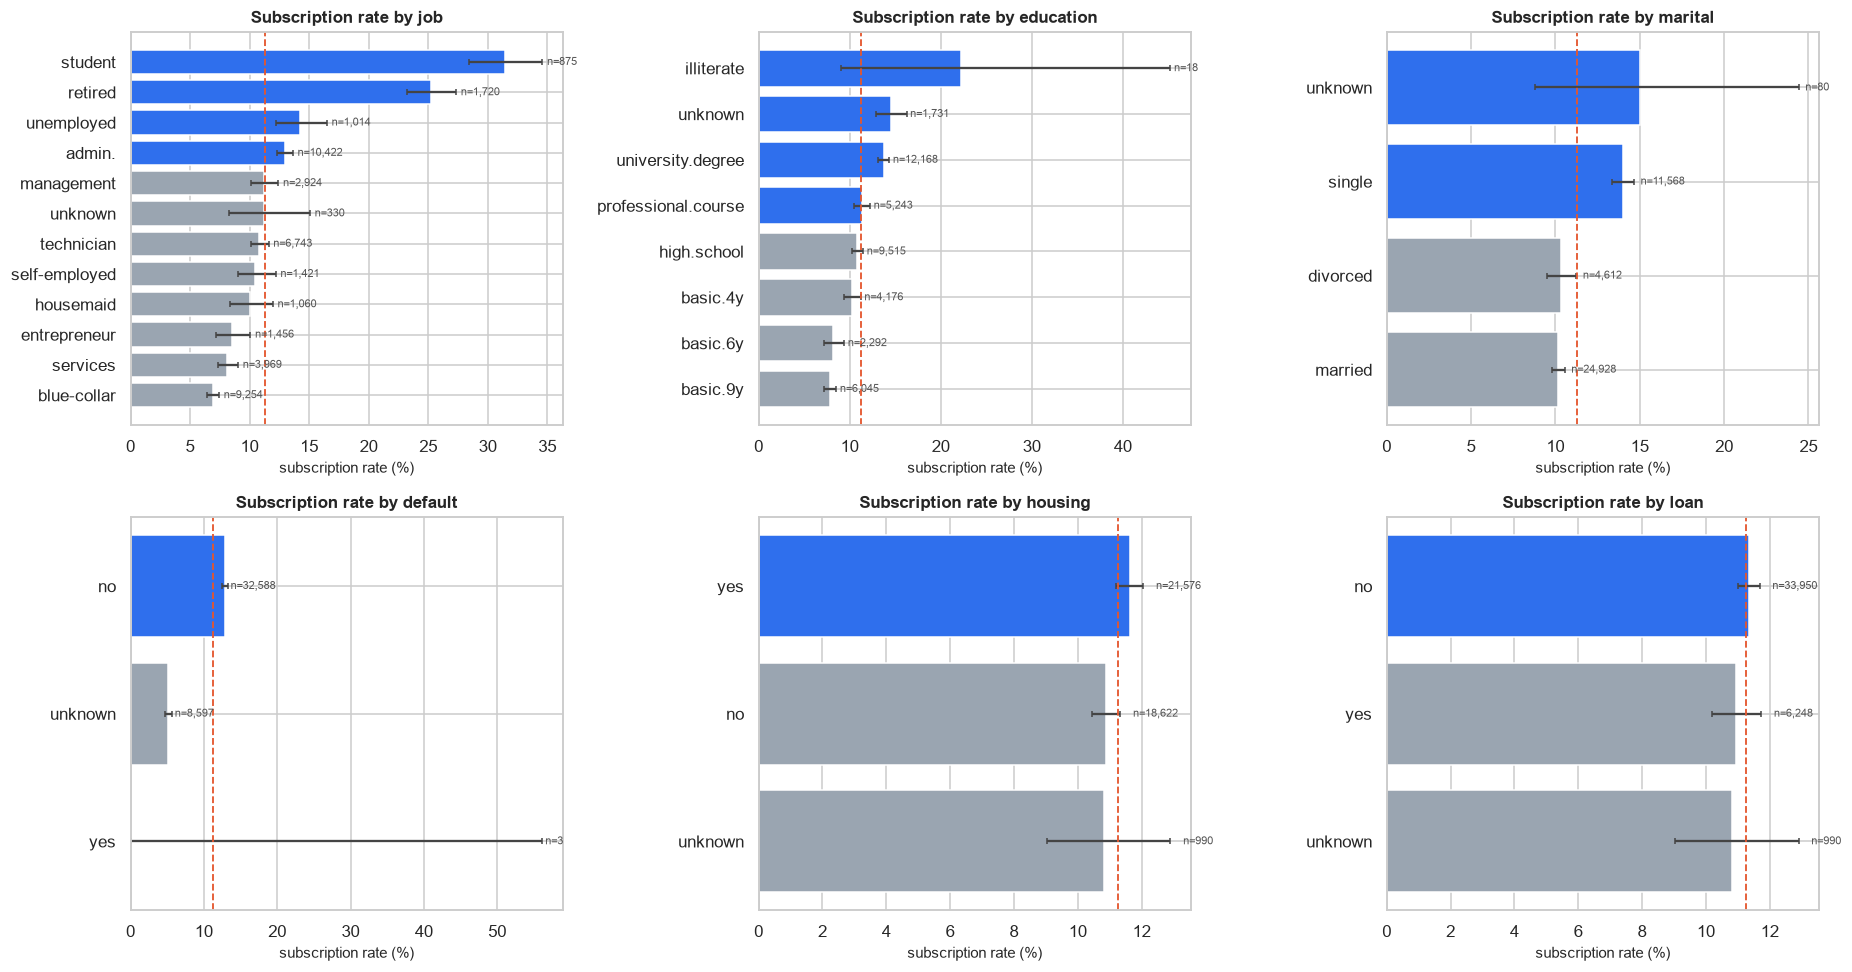

In [16]:
client_cats = ["job", "education", "marital", "default", "housing", "loan"]
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
rate_tabs = {}
for a, c in zip(ax.ravel(), client_cats):
    t = ec.rate_table(eda, c)
    rate_tabs[c] = t
    rate_bars(a, t, f"Subscription rate by {c}", BASE)
plt.tight_layout(); save_fig("eda_rate_client")

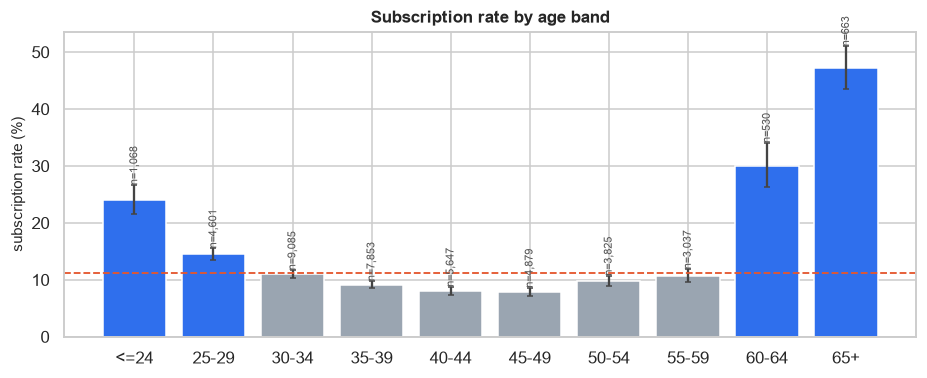

,contacts,rate_%,ci_low_%,ci_high_%,lift_vs_overall
age_band,,,,,
<=24,1068,23.970,21.510,26.620,2.130
25-29,4601,14.480,13.490,15.520,1.280
30-34,9085,11.010,10.380,11.670,0.980
35-39,7853,9.100,8.490,9.760,0.810
40-44,5647,8.020,7.340,8.760,0.710
45-49,4879,7.810,7.090,8.600,0.690
50-54,3825,9.730,8.830,10.710,0.860
55-59,3037,10.700,9.650,11.850,0.950
60-64,530,30.000,26.250,34.030,2.660


In [17]:
age_bins = [16, 24, 29, 34, 39, 44, 49, 54, 59, 64, 100]
age_labels = ["<=24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54", "55-59", "60-64", "65+"]
eda["age_band"] = pd.cut(eda["age"], age_bins, labels=age_labels)
t_age = ec.rate_table(eda, "age_band", order=age_labels)
fig, ax = plt.subplots(figsize=(10, 3.6))
rate_bars(ax, t_age, "Subscription rate by age band", BASE, horizontal=False)
save_fig("eda_rate_age")
display(t_age[["contacts", "rate_%", "ci_low_%", "ci_high_%", "lift_vs_overall"]])

**Reading.** Rates differ clearly between job groups: **students and retired clients subscribe far more often than blue-collar or services clients** (in the official file roughly 31% and 25% against about 7-8%). Age shows the same story in another form: the youngest and the oldest bands subscribe most, the middle of the working-age range least (a U-shape), which is why age is kept as a number rather than reduced to a linear trend. Education, marital status and loans show weaker, smaller differences. **`default = unknown`** separates from `no`, matching the finding in 3.4.

*Caution for later.* Job, age and marital status describe protected or sensitive characteristics. A model may legitimately use them to rank clients, but a bank must check that it does not systematically deprioritise a group; this is audited in notebook 07.

### 6.2 Campaign attributes

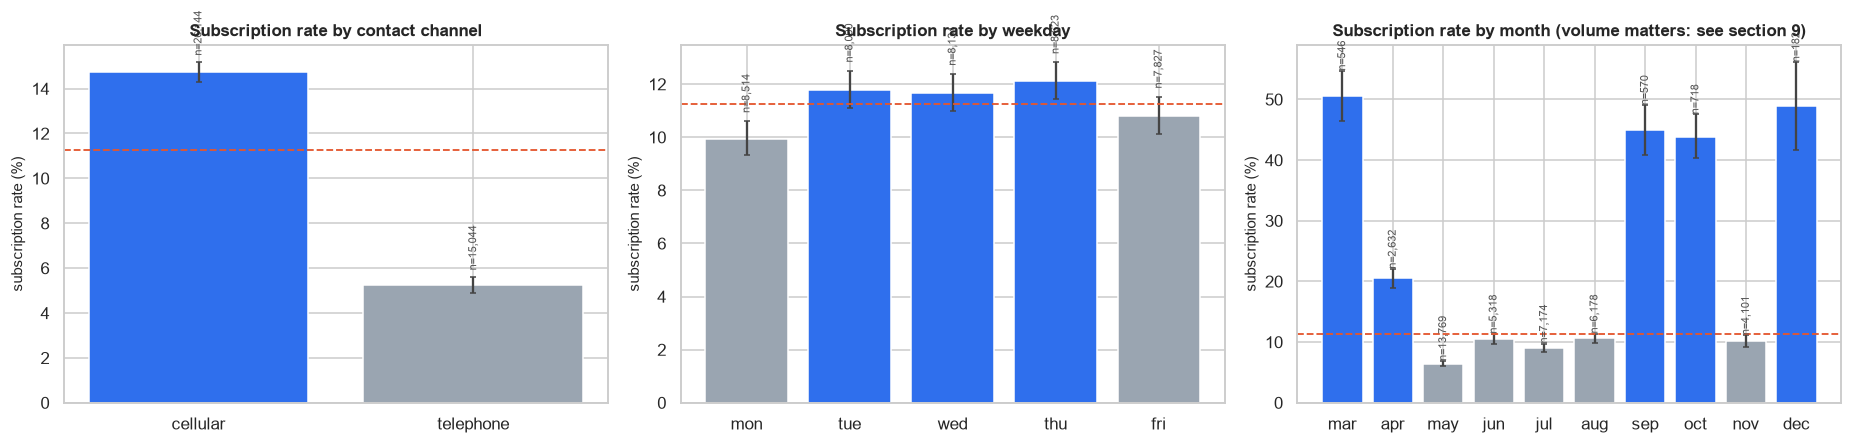

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
rate_bars(ax[0], ec.rate_table(eda, "contact"), "Subscription rate by contact channel", BASE, horizontal=False)
rate_bars(ax[1], ec.rate_table(eda, "day_of_week", order=["mon", "tue", "wed", "thu", "fri"]), "Subscription rate by weekday", BASE, horizontal=False)
rate_bars(ax[2], ec.rate_table(eda, "month", order=month_present), "Subscription rate by month (volume matters: see section 9)", BASE, horizontal=False)
plt.tight_layout(); save_fig("eda_rate_campaign")

**Reading.** The **channel** matters (mobile contact converts more often than the fixed telephone). The **weekday** barely matters. **Month looks like the strongest pattern of all**, but this is misleading: the months with the highest rates (March, September, October, December) are also the months with the *fewest calls*, and, as section 9 shows, they fall in different years with very different economic conditions. Month is therefore partly a **calendar proxy** and needs the time analysis before it can be interpreted.

### 6.3 Which attributes carry the most signal?
**Question.** A ranking on one scale helps decide where feature work should go. Categorical columns are scored by Cramér's V (0 = unrelated, 1 = perfectly related); numeric columns by a rank-based effect size; **mutual information** puts both on one comparable scale. `duration` is flagged in red: it will rank near the top because it is part of the outcome, not because it is useful.

,kind,effect_name,effect_size,p_value,mutual_info,flag
column,,,,,,
duration,numeric,|2*AUC-1|,0.637,0.000,0.072,post-call: leakage
nr.employed,numeric,|2*AUC-1|,0.498,0.000,0.062,
euribor3m,numeric,|2*AUC-1|,0.487,0.000,0.055,
previous,numeric,|2*AUC-1|,0.219,0.000,0.043,
pdays,numeric,|2*AUC-1|,0.194,0.000,0.042,
emp.var.rate,numeric,|2*AUC-1|,0.433,0.000,0.041,
poutcome,categorical,Cramer's V,0.320,0.000,0.030,
cons.conf.idx,numeric,|2*AUC-1|,0.075,0.000,0.027,
month,categorical,Cramer's V,0.274,0.000,0.026,


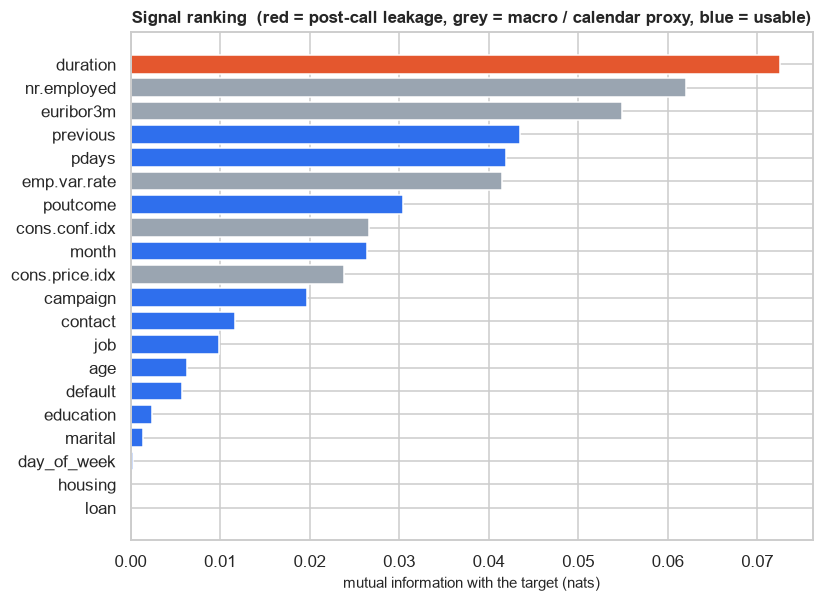

Strongest USABLE pre-call attributes: previous, pdays, poutcome, month, campaign


In [19]:
sig = ec.signal_table(eda, CATEGORICAL_RAW, NUMERIC_RAW)
sig.to_csv(TABLES_DIR / "eda_signal_ranking.csv")
display(sig[["kind", "effect_name", "effect_size", "p_value", "mutual_info", "flag"]].round(4))

fig, ax = plt.subplots(figsize=(8, 6))
s = sig["mutual_info"].sort_values()
cols = [C_WARN if c in LEAKY else (C_GREY if c in MACRO_COLS else C_MAIN) for c in s.index]
ax.barh(s.index, s.values, color=cols); ax.set_xlabel("mutual information with the target (nats)")
ax.set_title("Signal ranking  (red = post-call leakage, grey = macro / calendar proxy, blue = usable)")
save_fig("eda_signal_ranking")
usable = sig[(sig["flag"] == "") & (~sig.index.isin(MACRO_COLS))]
print("Strongest USABLE pre-call attributes:", ", ".join(usable.index[:5]))

**Reading.** Once `duration` (leakage) and the macro/calendar columns are set aside, the strongest attributes are the **previous-campaign outcome and history** (`poutcome`, `pdays`, `previous`), the **contact channel and month**, and then **job / education**. `age` scores close to zero here only because its effect is U-shaped (high for the youngest and oldest, low in between), which a monotone score cannot see: the age-band table in 6.1 shows it clearly matters. `housing` and `loan` are weak, and `default` matters mainly through its `unknown` level. This ranking is *univariate*: it says which single columns are informative, not which combination a model will use, and it makes no causal claim.

---
## 7 · Previous-campaign history

**Purpose.** A client who bought in an earlier campaign is the most natural person to call again. The question is how many such clients exist and how much of the campaign's success they explain.

,contacts,share_of_contacts_%,subscribers,rate_%,lift_vs_overall
poutcome,,,,,
success,1373,3.330,894,65.110,5.780
failure,4252,10.320,605,14.230,1.260
nonexistent,35563,86.340,3141,8.830,0.780


Clients who subscribed in an earlier campaign: 1,373 = 3.3% of all contacts, yet 19.3% of all subscribers; their rate is 65% vs 11.3% overall.


,contacts,rate_%,ci_low_%,ci_high_%
recency,,,,
0-3,541,65.250,61.140,69.140
4-6,576,66.150,62.190,69.890
7-10,194,60.310,53.290,66.930
11-15,166,57.830,50.230,65.080
16+,38,52.630,37.260,67.520


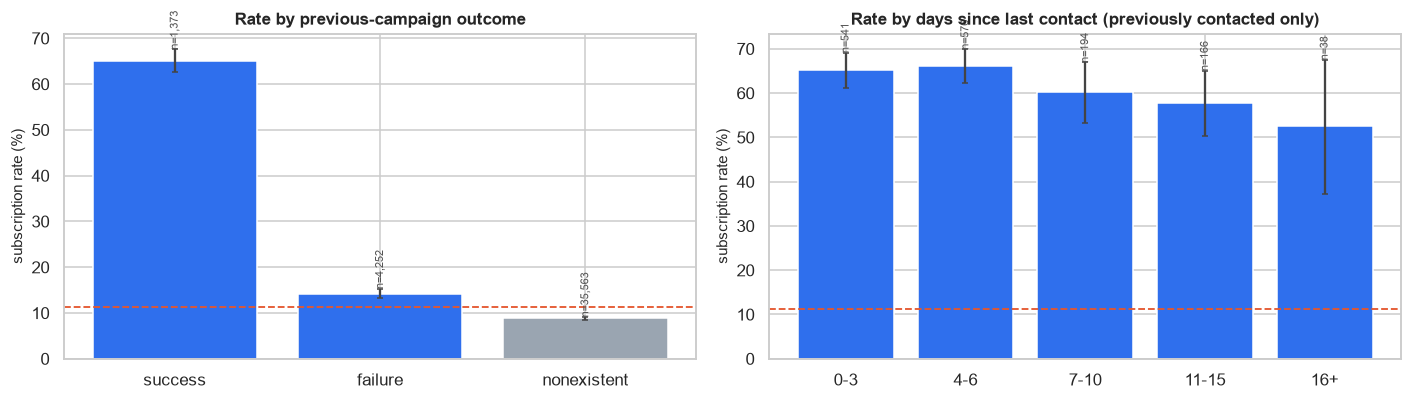

In [20]:
t_pout = ec.rate_table(eda, "poutcome")
display(t_pout[["contacts", "share_of_contacts_%", "subscribers", "rate_%", "lift_vs_overall"]])

succ = eda[eda["poutcome"] == "success"]
print(f"Clients who subscribed in an earlier campaign: {len(succ):,} = {100 * len(succ) / len(eda):.1f}% of all contacts, "
      f"yet {100 * succ['y_bin'].sum() / eda['y_bin'].sum():.1f}% of all subscribers; their rate is {100 * succ['y_bin'].mean():.0f}% vs {100 * BASE:.1f}% overall.")

contacted = eda[eda["pdays"] != 999].copy()
contacted["recency"] = pd.cut(contacted["pdays"], [-1, 3, 6, 10, 15, 100], labels=["0-3", "4-6", "7-10", "11-15", "16+"])
t_rec = ec.rate_table(contacted, "recency", order=["0-3", "4-6", "7-10", "11-15", "16+"])
display(t_rec[["contacts", "rate_%", "ci_low_%", "ci_high_%"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
rate_bars(ax[0], t_pout, "Rate by previous-campaign outcome", BASE, horizontal=False)
rate_bars(ax[1], t_rec, "Rate by days since last contact (previously contacted only)", BASE, horizontal=False)
plt.tight_layout(); save_fig("eda_history")

**Reading.** A previous **success** is by far the strongest single predictor available before the call: this small group (a few per cent of contacts) subscribes at several times the average rate and supplies a disproportionate share of all subscribers. Previous *failures* still subscribe somewhat above never-contacted clients (about 14% against 9%), but far below previous successes (about 65%). How *recently* a client was contacted shows a weaker, noisier pattern because each recency bucket holds few contacts.

**Decision.** Keep `poutcome`, `previous`, `pdays`; add `was_contacted_before`. The proposal's extra families (a "recent vs late" `pdays` split and a "previous success" flag) are tested, not assumed, in notebook 02 (section 6).

---
## 8 · Contact pressure: do repeated calls pay off?

**Purpose.** Calls cost money. If the tenth call to the same client almost never converts, the bank is spending effort on the wrong clients. `campaign` is the number of calls to a client during this campaign (so a client with `campaign = 5` consumed five calls).

,clients,calls,subscribers,rate_%,subscribers_per_100_calls,share_of_all_calls_%,share_of_subscribers_%
campaign,,,,,,,
1,17642,17642,2300,13.040,13.040,16.680,49.570
2,10570,21140,1211,11.460,5.730,19.990,26.100
3,5341,16023,574,10.750,3.580,15.150,12.370
4-5,4250,18599,369,8.680,1.980,17.590,7.950
6-9,2291,16024,147,6.420,0.920,15.150,3.170
10+,1094,16326,39,3.560,0.240,15.440,0.840


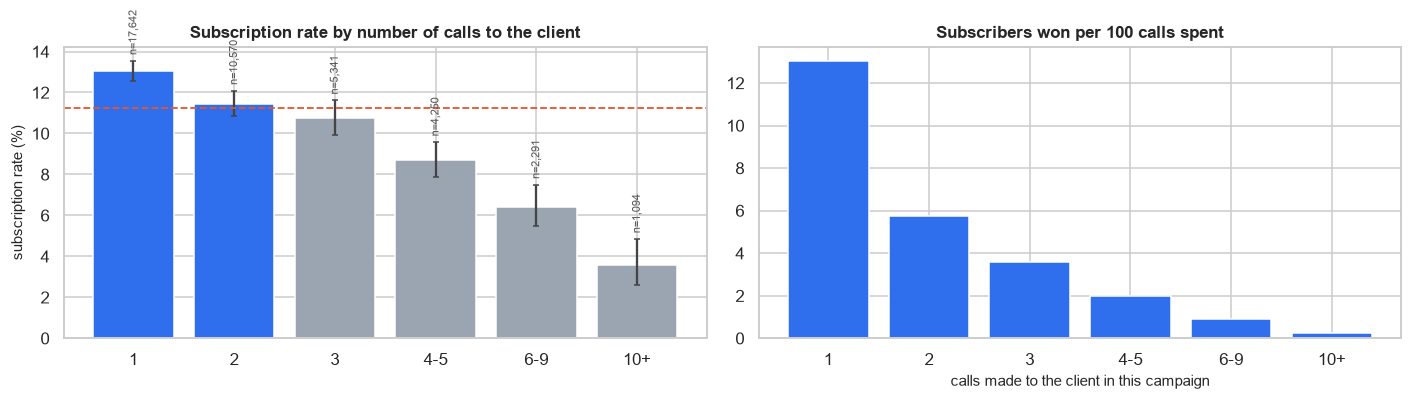

Clients called 6+ times absorb 30.6% of all calls but yield only 4.0% of subscribers.


In [21]:
bands = pd.cut(eda["campaign"], [0, 1, 2, 3, 5, 9, 100], labels=["1", "2", "3", "4-5", "6-9", "10+"])
g = eda.groupby(bands, observed=True).agg(clients=("y_bin", "size"), calls=("campaign", "sum"), subscribers=("y_bin", "sum"))
g["rate_%"] = 100 * g["subscribers"] / g["clients"]
g["subscribers_per_100_calls"] = 100 * g["subscribers"] / g["calls"]
g["share_of_all_calls_%"] = 100 * g["calls"] / g["calls"].sum()
g["share_of_subscribers_%"] = 100 * g["subscribers"] / g["subscribers"].sum()
display(g.round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
t_c = ec.rate_table(eda.assign(cb=bands), "cb", order=list(g.index))
rate_bars(ax[0], t_c, "Subscription rate by number of calls to the client", BASE, horizontal=False)
ax[1].bar(g.index.astype(str), g["subscribers_per_100_calls"], color=C_MAIN); ax[1].set_title("Subscribers won per 100 calls spent")
ax[1].set_xlabel("calls made to the client in this campaign")
plt.tight_layout(); save_fig("eda_contact_pressure")
heavy = g.loc[g.index.isin(["6-9", "10+"])]
print(f"Clients called 6+ times absorb {heavy['share_of_all_calls_%'].sum():.1f}% of all calls but yield only {heavy['share_of_subscribers_%'].sum():.1f}% of subscribers.")

**Reading.** The success rate falls as the number of calls rises, and the *subscribers won per 100 calls* drops even faster: persistent calling is the least efficient use of call-centre time. This is a useful business message in its own right (a cap on repeat calls would free capacity), but it comes with a **causal caveat**: clients who say yes stop being called, so a high `campaign` count partly *records* a refusal rather than causing one. That is why `campaign` sits in the grey zone of section 2 and is stress-tested in notebook 02.

---
## 9 · Time structure and drift

**Purpose.** The calls span roughly two and a half years (May 2008 to November 2010), through a financial crisis. If the response behaviour changes over that period, a model that is trained and tested on randomly shuffled rows will look much better than it will in a real future campaign, and the bank would be misled about its value. This section is the evidence for the **validation design** of the whole project.

### 9.1 Recovering the calendar from the file
The file is sorted by contact date but has **no date column**: only the `month`. A new year starts whenever the month number falls back (for example December → March). We rebuild `year` and `period` this way and **check the result** against the documented range of the data.

In [22]:
per = ec.reconstruct_periods(eda)
eda = eda.join(per[["year", "period", "period_idx"]])
by_p = eda.groupby("period", sort=False).agg(contacts=("y_bin", "size"), subscribers=("y_bin", "sum"), euribor3m=("euribor3m", "mean"))
by_p["rate_%"] = 100 * by_p["subscribers"] / by_p["contacts"]
print(f"Reconstructed {by_p.shape[0]} month-periods: first = {by_p.index[0]}, last = {by_p.index[-1]} (documented range: 2008-05 to 2010-11)")
print("Rows per reconstructed year:", eda["year"].value_counts().sort_index().to_dict())
display(by_p.round(2).T)

Reconstructed 26 month-periods: first = 2008-05, last = 2010-11 (documented range: 2008-05 to 2010-11)
Rows per reconstructed year: {2008: 27690, 2009: 11440, 2010: 2058}


period,2008-05,2008-06,2008-07,2008-08,2008-10,2008-11,2008-12,2009-03,2009-04,2009-05,2009-06,2009-07,2009-08,2009-09,2009-10,2009-11,2009-12,2010-03,2010-04,2010-05,2010-06,2010-07,2010-08,2010-09,2010-10,2010-11
contacts,"7,763.000","4,374.000","6,685.000","5,175.000",67.000,"3,616.000",10.000,282.000,"2,458.000","5,794.000",715.000,178.000,770.000,267.000,447.000,357.000,172.000,264.000,174.000,212.000,229.000,311.000,233.000,303.000,204.000,128.000
subscribers,240.000,188.000,407.000,271.000,42.000,190.000,1.000,126.000,442.000,524.000,264.000,66.000,264.000,106.000,180.000,168.000,88.000,150.000,97.000,122.000,107.000,176.000,120.000,150.000,93.000,58.000
euribor3m,4.860,4.930,4.960,4.960,4.920,4.110,3.490,1.650,1.410,1.290,1.260,1.030,0.870,0.780,0.740,0.720,0.710,0.650,0.650,0.690,0.730,0.850,0.900,0.880,1.000,1.040
rate_%,3.090,4.300,6.090,5.240,62.690,5.250,10.000,44.680,17.980,9.040,36.920,37.080,34.290,39.700,40.270,47.060,51.160,56.820,55.750,57.550,46.720,56.590,51.500,49.500,45.590,45.310


### 9.2 Volume, response rate and the economy over time

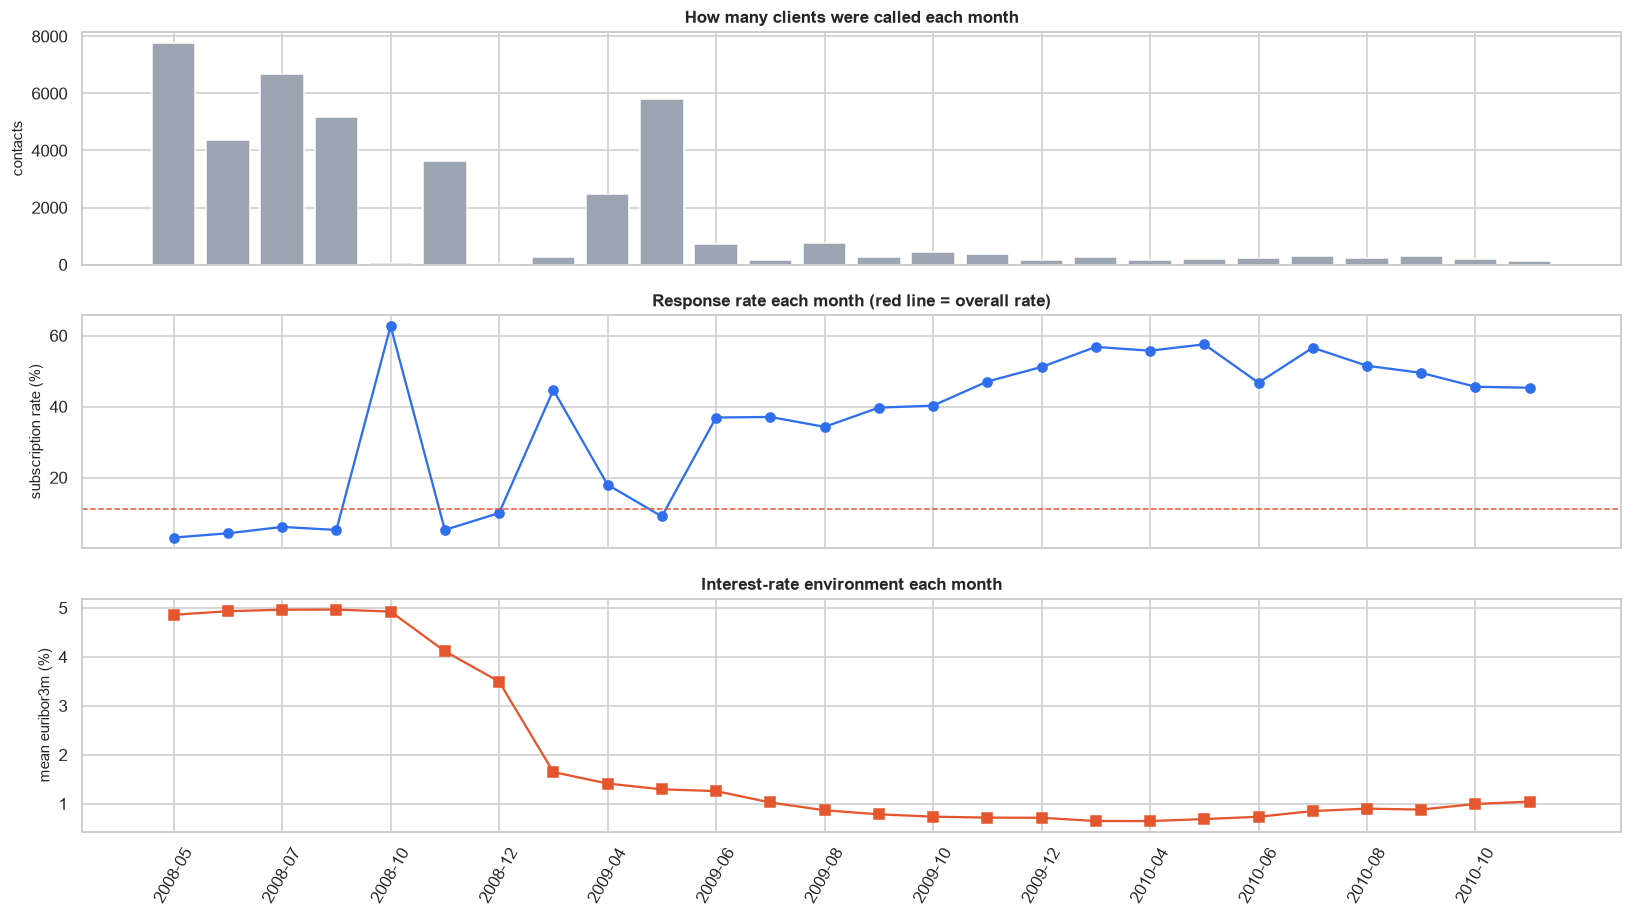

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(15, 8.5), sharex=True)
x = np.arange(len(by_p))
ax[0].bar(x, by_p["contacts"], color=C_GREY); ax[0].set_ylabel("contacts"); ax[0].set_title("How many clients were called each month")
ax[1].plot(x, by_p["rate_%"], marker="o", color=C_MAIN); ax[1].axhline(100 * BASE, color=C_WARN, ls="--", lw=1)
ax[1].set_ylabel("subscription rate (%)"); ax[1].set_title("Response rate each month (red line = overall rate)")
ax[2].plot(x, by_p["euribor3m"], marker="s", color=C_WARN); ax[2].set_ylabel("mean euribor3m (%)"); ax[2].set_title("Interest-rate environment each month")
ax[2].set_xticks(x[::2], by_p.index[::2], rotation=60)
plt.tight_layout(); save_fig("eda_time_drift")

### 9.3 Is `month` seasonality, or is it the year?
If a month's rate were seasonal, the same month would look similar in 2008, 2009 and 2010. The grid below shows the rate (top) and the number of contacts (bottom) for each month and year. Cells with fewer than 30 contacts are blanked: their rates are not reliable.

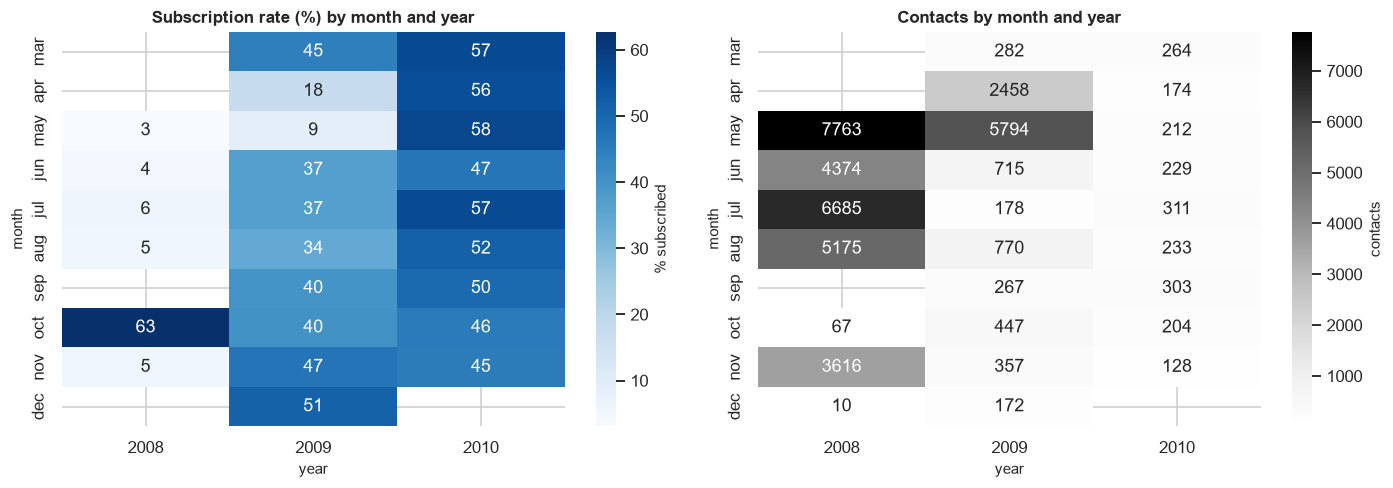

In [24]:
piv_rate = eda.pivot_table(index="month", columns="year", values="y_bin", aggfunc="mean").reindex(month_present) * 100
piv_n = eda.pivot_table(index="month", columns="year", values="y_bin", aggfunc="size").reindex(month_present)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
sns.heatmap(piv_rate.where(piv_n >= 30), annot=True, fmt=".0f", cmap="Blues", ax=ax[0], cbar_kws={"label": "% subscribed"})
ax[0].set_title("Subscription rate (%) by month and year")
sns.heatmap(piv_n, annot=True, fmt=".0f", cmap="Greys", ax=ax[1], cbar_kws={"label": "contacts"}); ax[1].set_title("Contacts by month and year")
plt.tight_layout(); save_fig("eda_month_year")

### 9.4 Did the *kind of client being called* change?
A rising response rate could mean clients became more willing, or that the bank started calling a different mix of clients. Both are drift; they call for different remedies.

In [25]:
comp = eda.groupby("year").agg(
    contacts=("y_bin", "size"), rate_pct=("y_bin", lambda s: 100 * s.mean()),
    mean_age=("age", "mean"),
    pct_cellular=("contact", lambda s: 100 * (s == "cellular").mean()),
    pct_previously_contacted=("pdays", lambda s: 100 * (s != 999).mean()),
    pct_retired_or_student=("job", lambda s: 100 * s.isin(["retired", "student"]).mean()),
    mean_calls_per_client=("campaign", "mean"),
    mean_euribor3m=("euribor3m", "mean"))
display(comp.round(2))

,contacts,rate_pct,mean_age,pct_cellular,pct_previously_contacted,pct_retired_or_student,mean_calls_per_client,mean_euribor3m
year,,,,,,,,
2008,27690,4.840,40.200,50.470,0.130,3.570,2.800,4.820
2009,11440,19.480,39.260,91.770,6.600,9.820,2.130,1.230
2010,2058,52.140,41.950,81.150,35.230,23.470,1.910,0.810


### 9.5 What this means for how we split and validate

,rows,subscribers,response_rate_%
part,,,
train,32940,2100,6.380
pilot,500,32,6.400
test,7736,2507,32.410


Response rate in each forward-chaining validation block (inside the training period): [4.4, 6.3, 5.5, 12.7] %
Overall rate 11.3%. A stratified random split would give every part about 11.3%, hiding all of this.


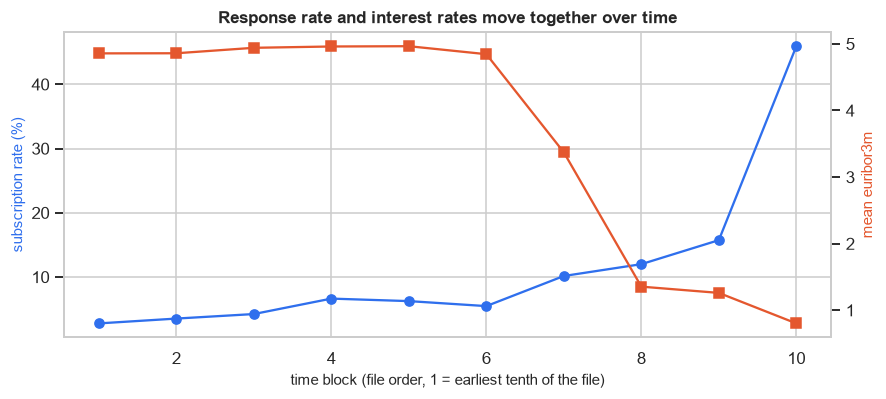

In [26]:
dedup = deduplicate(raw)
sp = chronological_split(dedup)
display(describe_split(sp).assign(response_rate=lambda d: (100 * d["response_rate"]).round(2)).rename(columns={"response_rate": "response_rate_%"}))

from sklearn.model_selection import TimeSeriesSplit
y_all = sp["y_all"][: sp["cut"]]
fc_rates = [round(100 * float(y_all[va].mean()), 1) for _, va in TimeSeriesSplit(n_splits=N_TS_SPLITS).split(y_all)]
print(f"Response rate in each forward-chaining validation block (inside the training period): {fc_rates} %")
print(f"Overall rate {100 * BASE:.1f}%. A stratified random split would give every part about {100 * BASE:.1f}%, hiding all of this.")

blocks = pd.qcut(np.arange(len(eda)), 10, labels=False) + 1
tb = eda.groupby(blocks).agg(rate=("y_bin", "mean"), euribor=("euribor3m", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tb.index, 100 * tb["rate"], marker="o", color=C_MAIN); ax.set_ylabel("subscription rate (%)", color=C_MAIN)
ax2 = ax.twinx(); ax2.plot(tb.index, tb["euribor"], marker="s", color=C_WARN); ax2.set_ylabel("mean euribor3m", color=C_WARN)
ax.set_xlabel("time block (file order, 1 = earliest tenth of the file)"); ax.set_title("Response rate and interest rates move together over time")
ax2.grid(False); save_fig("eda_time_blocks")

**Reading.** The response rate **does not stay level**: it is about 3-6% through 2008, rises from March 2009 once interest rates fall, and sits around 45-57% in 2010 (the held-out test period is about 32%, the training period about 6%). The mix of clients also shifts between years (9.4). Two consequences follow:

* The later part of the file is **a different world**. A chronological split (train on the past, test on the future) is the only honest simulation of a real campaign, and it will report a harder, lower, *more truthful* score than a random split. The size of that optimism is measured in notebook 05 (section 5).
* **Model selection inside the training period also uses forward-chaining folds**, not just shuffled folds, for the same reason (notebook 03).
* Because response rate differs so much between the training and the test period, **raw predicted probabilities will not match the later base rate**. The call policy therefore ranks clients and re-anchors the base rate with recent labelled calls (notebook 06).

---
## 10 · Correlation and redundancy

**Purpose.** Strongly overlapping columns carry the same information twice. For tree models that is harmless; for linear coefficients it makes them unstable; and if the overlap is *with the calendar* it is a warning that the column describes the period, not the client.

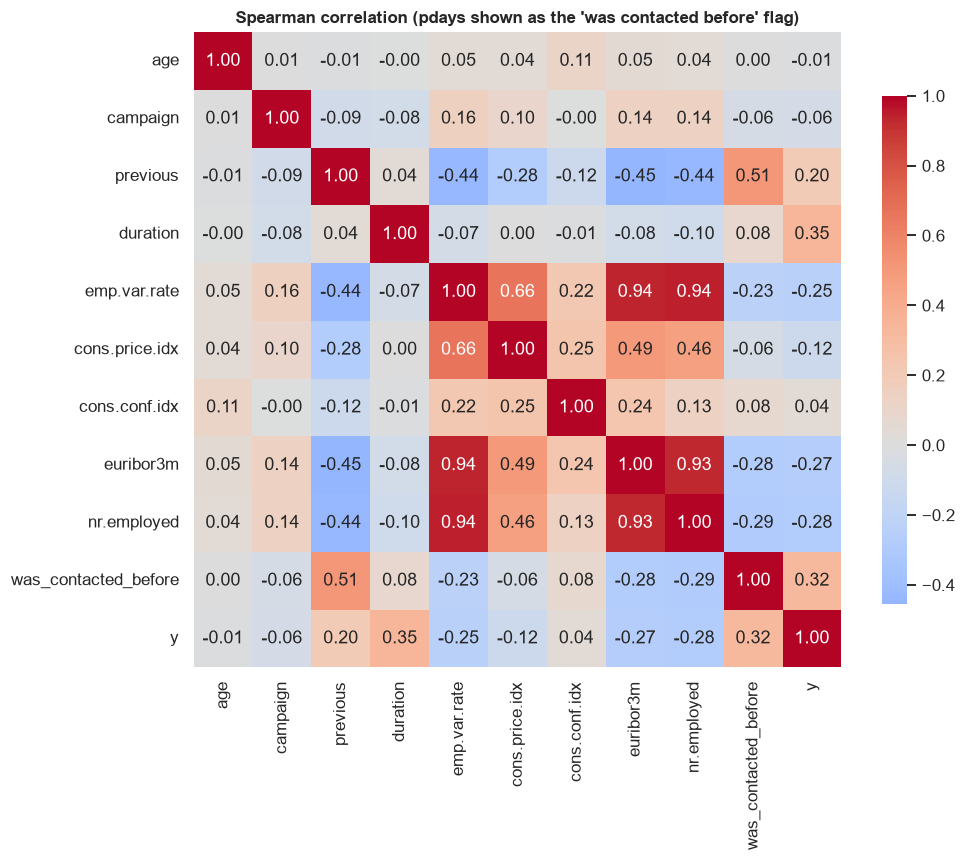

Macro-indicator pairs with |r| >= 0.9: 3 of 10  (highest 0.97)

Variance inflation factors (VIF > 10 = severe collinearity):


column,euribor3m,emp.var.rate,nr.employed,cons.price.idx,cons.conf.idx,previous,campaign,age
vif,64.300,33.100,31.600,6.300,2.600,1.300,1.000,1.000



Spearman correlation of each macro indicator with TIME (rank of the calendar period):


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
rho with time,-0.670,-0.760,-0.260,-0.630,-0.580


For comparison, usable client / history columns:


,age,campaign,previous
rho with time,-0.050,-0.110,0.460


In [27]:
num_view = eda[["age", "campaign", "previous", "duration"] + MACRO_COLS].copy()
num_view["was_contacted_before"] = (eda["pdays"] != 999).astype(int)
num_view["y"] = eda["y_bin"]
corr = num_view.corr(method="spearman")
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"shrink": .8})
plt.title("Spearman correlation (pdays shown as the 'was contacted before' flag)")
save_fig("eda_correlation")

macro_corr = pd.Series(eda[MACRO_COLS].corr().abs().values[np.triu_indices(5, 1)])
print(f"Macro-indicator pairs with |r| >= 0.9: {int((macro_corr >= 0.9).sum())} of {len(macro_corr)}  (highest {macro_corr.max():.2f})")
print("\nVariance inflation factors (VIF > 10 = severe collinearity):")
display(ec.vif_table(eda, MACRO_COLS + ["age", "campaign", "previous"]).T)
print("\nSpearman correlation of each macro indicator with TIME (rank of the calendar period):")
display(pd.Series({c: stats.spearmanr(eda[c], eda["period_idx"])[0] for c in MACRO_COLS}, name="rho with time").round(2).to_frame().T)
print("For comparison, usable client / history columns:")
display(pd.Series({c: stats.spearmanr(eda[c], eda["period_idx"])[0] for c in ["age", "campaign", "previous"]}, name="rho with time").round(2).to_frame().T)

**Reading.** Three of the five macro indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are almost the same variable (correlation about 0.9 or more, very high VIF), and they are all **strongly tied to the calendar**. They also correlate with the target in this period (the bank's response rose as rates fell), but a model that learns "low Euribor ⇒ subscribe" has learned *the 2010 economy*, not *which client is receptive*, and it would fail in a different year. Client and history columns, by contrast, hardly move with time.

**Decision (policy, tested later).** Macro indicators are **excluded by default** (`EXCLUDE_MACRO = True` in `src/config.py`), with the evidence demanded in notebook 03 (section 5: variants with and without macro features, scored on forward-chaining folds and the later hold-out) rather than a verdict from correlations alone. The rank correlation of `duration` with the outcome (about 0.35 in section 12) is by far the largest of any input and is *not* a virtue: see the leakage demonstration in notebook 02.

---
## 11 · Profile of a subscriber

**Purpose.** A campaign manager thinks in client types, not in p-values. This section restates the findings as one table (subscribers vs the rest) and then lists the single groups with the highest lift, restricted to groups large enough to be trusted.

In [28]:
def pct(mask): return 100 * mask.mean()
profile = pd.DataFrame({
    "subscribers": eda[eda["y_bin"] == 1].pipe(lambda d: pd.Series({
        "median age": d["age"].median(), "% retired or student": pct(d["job"].isin(["retired", "student"])),
        "% blue-collar or services": pct(d["job"].isin(["blue-collar", "services"])),
        "% university degree": pct(d["education"] == "university.degree"), "% with housing loan": pct(d["housing"] == "yes"),
        "% contacted by mobile": pct(d["contact"] == "cellular"), "% previously contacted": pct(d["pdays"] != 999),
        "% previous campaign success": pct(d["poutcome"] == "success"), "mean calls in this campaign": d["campaign"].mean()})),
    "non-subscribers": eda[eda["y_bin"] == 0].pipe(lambda d: pd.Series({
        "median age": d["age"].median(), "% retired or student": pct(d["job"].isin(["retired", "student"])),
        "% blue-collar or services": pct(d["job"].isin(["blue-collar", "services"])),
        "% university degree": pct(d["education"] == "university.degree"), "% with housing loan": pct(d["housing"] == "yes"),
        "% contacted by mobile": pct(d["contact"] == "cellular"), "% previously contacted": pct(d["pdays"] != 999),
        "% previous campaign success": pct(d["poutcome"] == "success"), "mean calls in this campaign": d["campaign"].mean()})),
})
profile["difference"] = profile["subscribers"] - profile["non-subscribers"]
display(profile.round(2))

rows = []
for c in ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome", "day_of_week"]:
    for lvl, r in ec.rate_table(eda, c, min_n=300).iterrows():
        rows.append(dict(group=f"{c} = {lvl}", contacts=int(r["contacts"]), rate_pct=r["rate_%"], lift=r["lift_vs_overall"]))
lifts = pd.DataFrame(rows).set_index("group").sort_values("lift", ascending=False)
print("Highest-lift single groups (at least 300 contacts):")
display(lifts.head(8).round(2))
print("Lowest-lift single groups:")
display(lifts.tail(5).round(2))

,subscribers,non-subscribers,difference
median age,37.000,38.000,-1.000
% retired or student,15.280,5.160,10.120
% blue-collar or services,20.710,33.550,-12.840
% university degree,35.990,28.720,7.270
% with housing loan,54.030,52.180,1.850
% contacted by mobile,83.040,60.990,22.050
% previously contacted,20.840,1.500,19.340
% previous campaign success,19.270,1.310,17.960
mean calls in this campaign,2.050,2.630,-0.580


Highest-lift single groups (at least 300 contacts):


,contacts,rate_pct,lift
group,,,
poutcome = success,1373,65.110,5.780
job = student,875,31.430,2.790
job = retired,1720,25.230,2.240
contact = cellular,26144,14.740,1.310
education = unknown,1731,14.500,1.290
poutcome = failure,4252,14.230,1.260
job = unemployed,1014,14.200,1.260
marital = single,11568,14.000,1.240


Lowest-lift single groups:


,contacts,rate_pct,lift
group,,,
job = services,3969,8.140,0.720
education = basic.9y,6045,7.820,0.690
job = blue-collar,9254,6.890,0.610
default = unknown,8597,5.150,0.460
contact = telephone,15044,5.230,0.460


**Reading.** The typical subscriber is **not** a different "kind of person" in every respect: they are more often retired or students, more often reached on a mobile phone, and far more often someone who subscribed before. Lift figures show where a single rule would already beat random calling (for instance "call previous-campaign successes first"), and also how limited any single-attribute rule is: it covers only a small share of subscribers. That is the argument for a model that combines attributes, which is what notebooks 03-04 build.

---
## 12 · EDA insight log

Every finding is recorded with the **evidence** (computed from the data just now, so it always matches the outputs above), the **consequence for the task**, and **where it is acted on**. This table is saved to `reports/tables/eda_insight_log.csv` and summarised in `docs/eda_insight_log.md`.

In [29]:
poutcome_s = ec.rate_table(eda, "poutcome").loc["success"] if "success" in set(eda["poutcome"]) else None
first_r, last_r = by_p["rate_%"].iloc[:3].mean(), by_p["rate_%"].iloc[-3:].mean()
insights = [
    ("E1", "Data quality", f"{int(raw.duplicated().sum())} exact duplicate rows and no empty cells in {len(raw):,} rows",
     "The file is clean apart from a few repeats; duplicates could leak across the split", "Drop duplicates, keep order (02 §3)"),
    ("E2", "Data quality", "Hidden missing values written as 'unknown': " + ", ".join(f"{c} {r.unknown_pct:.1f}%" for c, r in unk_cols.head(4).iterrows()),
     "Imputing would hide a real state of the client record; the label can be informative (3.4)", "Own category; education -> ordinal + missing indicator (02 §3)"),
    ("E3", "Data quality", f"pdays = 999 for {100 * (eda['pdays'] == 999).mean():.1f}% of rows; agrees with previous = 0 and poutcome = nonexistent",
     "999 is a code, not a number of days; a numeric 999 would distort distances and coefficients", "Flag was_contacted_before + replace by 0 (02 §3)"),
    ("E4", "Leakage", f"duration is the strongest column (Spearman with target {corr.loc['duration', 'y']:.2f}) but exists only after the call",
     "Would create an illusion of skill and cannot be used to build a call list", "Excluded from all deployable models; leakage demonstrated (02 §7)"),
    ("E5", "Target", f"Subscription rate {100 * BASE:.2f}%: about {1 / BASE:.1f} calls per subscription",
     "Accuracy is meaningless (always-no scores {:.1f}%)".format(100 * (1 - BASE)), "PR-AUC, ROC-AUC and budget metrics; imbalance tested (04)"),
    ("E6", "History", f"Previous-campaign successes: {100 * (eda['poutcome'] == 'success').mean():.1f}% of contacts, rate "
     f"{poutcome_s['rate_%'] if poutcome_s is not None else float('nan'):.0f}% (lift {poutcome_s['lift_vs_overall'] if poutcome_s is not None else float('nan'):.1f}x)",
     "Strongest pre-call predictor, but only for a small group", "Keep poutcome / previous / pdays; test extra pdays features (02 §6)"),
    ("E7", "Client", f"Highest-rate jobs: " + ", ".join(rate_tabs['job'].index[:2]) + "; lowest: " + ", ".join(rate_tabs['job'].index[-2:]),
     "Job and age separate clients (U-shape in age); sensitive attributes", "Keep job (one-hot) and age (numeric); fairness audit (07)"),
    ("E8", "Campaign", f"Clients called 6+ times use {heavy['share_of_all_calls_%'].sum():.0f}% of calls for {heavy['share_of_subscribers_%'].sum():.0f}% of subscribers",
     "Repeated calling is inefficient, but campaign partly records refusals (reverse causality)", "campaign kept + log copy; sensitivity test (02 §7)"),
    ("E9", "Campaign", "Month has the largest apparent effect; the high-rate months are the lowest-volume ones and belong to different years",
     "Month mixes seasonality with year / economy; rates on small months are noisy", "Keep month but validate chronologically (02 §5, 03)"),
    ("E10", "Drift", f"Response rate averages {first_r:.1f}% in the first three months of the file and {last_r:.1f}% in the last three",
     "The base rate and the client mix change over time; random splits would be over-optimistic", "Chronological train/pilot/test split; forward-chaining CV (02 §5, 03, 05)"),
    ("E11", "Macro", f"{int((macro_corr >= 0.9).sum())} macro pairs have |r| >= 0.9 and all five track the calendar (|rho with time| up to {max(abs(stats.spearmanr(eda[c], eda['period_idx'])[0]) for c in MACRO_COLS):.2f})",
     "Macro columns describe the period, not the client; collinear and time-proxy", "Excluded by default; tested with and without (03 §5)"),
    ("E12", "Skew", f"campaign skew {eda['campaign'].skew():.1f}, max {eda['campaign'].max()} calls; outliers are real behaviour",
     "A long tail hurts linear / neural models, not trees; removing rows would delete real clients", "Keep rows; add log1p(campaign) copy (02 §4)"),
]
insight_log = pd.DataFrame(insights, columns=["id", "theme", "evidence (computed)", "consequence for the task", "handled in"]).set_index("id")
insight_log.to_csv(TABLES_DIR / "eda_insight_log.csv")
with pd.option_context("display.max_colwidth", 200):
    display(insight_log)

,theme,evidence (computed),consequence for the task,handled in
id,,,,
E1,Data quality,"12 exact duplicate rows and no empty cells in 41,188 rows",The file is clean apart from a few repeats; duplicates could leak across the split,"Drop duplicates, keep order (02 §3)"
E2,Data quality,"Hidden missing values written as 'unknown': default 20.9%, education 4.2%, housing 2.4%, loan 2.4%",Imputing would hide a real state of the client record; the label can be informative (3.4),Own category; education -> ordinal + missing indicator (02 §3)
E3,Data quality,pdays = 999 for 96.3% of rows; agrees with previous = 0 and poutcome = nonexistent,"999 is a code, not a number of days; a numeric 999 would distort distances and coefficients",Flag was_contacted_before + replace by 0 (02 §3)
E4,Leakage,duration is the strongest column (Spearman with target 0.35) but exists only after the call,Would create an illusion of skill and cannot be used to build a call list,Excluded from all deployable models; leakage demonstrated (02 §7)
E5,Target,Subscription rate 11.27%: about 8.9 calls per subscription,Accuracy is meaningless (always-no scores 88.7%),"PR-AUC, ROC-AUC and budget metrics; imbalance tested (04)"
E6,History,"Previous-campaign successes: 3.3% of contacts, rate 65% (lift 5.8x)","Strongest pre-call predictor, but only for a small group",Keep poutcome / previous / pdays; test extra pdays features (02 §6)
E7,Client,"Highest-rate jobs: student, retired; lowest: services, blue-collar",Job and age separate clients (U-shape in age); sensitive attributes,Keep job (one-hot) and age (numeric); fairness audit (07)
E8,Campaign,Clients called 6+ times use 31% of calls for 4% of subscribers,"Repeated calling is inefficient, but campaign partly records refusals (reverse causality)",campaign kept + log copy; sensitivity test (02 §7)
E9,Campaign,Month has the largest apparent effect; the high-rate months are the lowest-volume ones and belong to different years,Month mixes seasonality with year / economy; rates on small months are noisy,"Keep month but validate chronologically (02 §5, 03)"


---
## 13 · Hand-off to preprocessing (notebook 02)

| Issue found in EDA | Decision | Where it is implemented | Where it is tested |
|---|---|---|---|
| 12 duplicate rows | Drop later copies, keep order | `src/data/splits.py::deduplicate` | notebook 02 §3 |
| `unknown` in job, marital, default, housing, loan | Keep as its own category | `OneHotEncoder` in `src/features/preprocessing.py` | notebook 02 §3 |
| `unknown` education | Ordinal + median imputation + missing indicator, inside the pipeline | `add_features`, `SimpleImputer(add_indicator=True)` | notebook 02 §3 |
| `pdays = 999` | `was_contacted_before` flag, placeholder → 0 | `add_features` | notebook 02 §3, `tests/` |
| Skewed `campaign` | Add `log1p` copy | `add_features` | notebook 02 §4 |
| Different scales | Standardise for linear / neural / SVM models only | `build_pipeline(scale=...)` | notebook 02 §4 |
| `duration` | Exclude (class C: known only after the call) | `build_pipeline` (never in `NUM_COLS`) | notebook 02 §7 |
| `campaign` grey zone | Keep, test its removal | `build_pipeline(exclude=...)` | notebook 02 §7 |
| Time drift | Chronological train / pilot / test split | `src/data/splits.py::chronological_split` | notebook 02 §5 |
| Macro indicators = calendar proxy | Excluded by default, tested | `EXCLUDE_MACRO` in `src/config.py` | notebook 03 §5 |
| Extra feature families named in the proposal | Adopt only if they help on forward-chaining folds | `add_features_v2`, `FE_GROUPS` | notebook 02 §6 |
| Rare class | Metrics that respect imbalance; resampling tested | `src/evaluation/metrics.py` | notebook 04 |

### What EDA cannot decide
EDA shows association, not prediction. Whether macro columns help *out of time*, whether the proposal's engineered features add anything, and whether resampling improves the ranking all need a model, a fair validation design and a pre-stated adoption rule. They are settled with evidence in notebooks 02-04, not asserted here.